In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

print("Capstone 1 environment is ready!")

Capstone 1 environment is ready!


In [8]:
# Locate our project folder
BASE_DIR = Path.cwd().parent

# Locate the raw data
DATA_DIR = BASE_DIR / "data" / "raw"

# Find our Excel workbook
excel_files = list(DATA_DIR.glob("*.xlsx"))

excel_files

[WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/data/raw/selected_food_table_May-25.xlsx')]

In [3]:
file_path = excel_files[0]

df_main = pd.read_excel(
    file_path,
    sheet_name="Selected Food May 2025"
)

df_zone = pd.read_excel(
    file_path,
    sheet_name="Zone All item"
)

In [9]:
display(df_main.head())
display(df_zone.head())

,Item Label,Average of May-24,Average of Apr-25,Average of May-25,MoM,YoY,Highest,Lowest
0,"Agric hen eggs,",160.310000,259.316152,265.725250,2.471538,65.757127,Enugu (364.62),Kaduna (230)
1,"Agric hen eggs, (a Crate of 30 pieces)",NaN,6281.529423,6263.915592,-0.280407,NaN,Enugu (8349.15),Niger (5301.68)
2,Beans Brown,2009.226080,2429.388572,2385.151863,-1.820899,18.709979,Abia (3548.02),Sokoto (1670.81)
3,Beans white,1847.836919,2097.309931,2040.508123,-2.708317,10.426851,Enugu (3021.67),Sokoto (1514.96)
4,Beef Boneless,5137.524647,6544.536858,6662.924662,1.808956,29.691342,Imo (9053.45),Yobe (5250)


,Item Label,NORTH CENTRAL,NORTH EAST,NORTH WEST,SOUTH EAST,SOUTH SOUTH,SOUTH WEST
0,"Agric hen eggs,",255.128762,259.157083,245.618254,308.022000,269.052544,269.539563
1,"Agric hen eggs, (a Crate of 30 pieces)",5842.542171,6113.333333,5744.360714,7441.279290,6297.543373,6497.483333
2,Beans Brown,2608.534068,2421.509722,1766.227223,3166.026322,2269.069104,2275.614220
3,Beans white,2052.672611,2141.812500,1580.276763,2705.752764,2120.597236,1827.488784
4,Beef Boneless,6374.469048,6383.333333,5793.599686,8540.136732,6894.341283,6497.500000


In [10]:
print("Main dataset shape:", df_main.shape)
print("Zone dataset shape:", df_zone.shape)

Main dataset shape: (42, 8)
Zone dataset shape: (42, 7)


In [11]:
df_main.info()

<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Item Label         42 non-null     str    
 1   Average of May-24  27 non-null     float64
 2   Average of Apr-25  42 non-null     float64
 3   Average of May-25  42 non-null     float64
 4   MoM                42 non-null     float64
 5   YoY                27 non-null     float64
 6   Highest            42 non-null     str    
 7   Lowest             42 non-null     str    
dtypes: float64(5), str(3)
memory usage: 2.8 KB


In [12]:
df_zone.info()

<class 'pandas.DataFrame'>
RangeIndex: 42 entries, 0 to 41
Data columns (total 7 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Item Label     42 non-null     str    
 1   NORTH CENTRAL  42 non-null     float64
 2   NORTH EAST     42 non-null     float64
 3   NORTH WEST     42 non-null     float64
 4   SOUTH EAST     42 non-null     float64
 5   SOUTH SOUTH    42 non-null     float64
 6   SOUTH WEST     42 non-null     float64
dtypes: float64(6), str(1)
memory usage: 2.4 KB


In [13]:
df_main.isnull().sum()

Item Label            0
Average of May-24    15
Average of Apr-25     0
Average of May-25     0
MoM                   0
YoY                  15
Highest               0
Lowest                0
dtype: int64

In [14]:
missing_percentage = (
    df_main.isnull().sum() / len(df_main)
) * 100

missing_percentage

Item Label            0.000000
Average of May-24    35.714286
Average of Apr-25     0.000000
Average of May-25     0.000000
MoM                   0.000000
YoY                  35.714286
Highest               0.000000
Lowest                0.000000
dtype: float64

In [15]:
missing_records = df_main[
    df_main["Average of May-24"].isnull()
]

display(missing_records)

,Item Label,Average of May-24,Average of Apr-25,Average of May-25,MoM,YoY,Highest,Lowest
1,"Agric hen eggs, (a Crate of 30 pieces)",NaN,6281.529423,6263.915592,-0.280407,NaN,Enugu (8349.15),Niger (5301.68)
5,"Bread (sliced), 450g",NaN,1688.399846,1657.587295,-1.824956,NaN,Ebonyi (1975.76),Yobe (900)
6,"Bread (unsliced), 450g",NaN,1547.517902,1556.056678,0.551772,NaN,Ebonyi (1937.5),Yobe (950)
7,"Carrots, fresh",NaN,1931.317857,1911.687162,-1.016440,NaN,Imo (3034.79),Borno (1097.91)
12,Cray fish small white,NaN,6655.661529,8046.835984,20.902121,NaN,Gombe (10000),Delta (6466.65)
13,"Dried fish, Bonga",NaN,6657.742776,6703.079156,0.680957,NaN,Ebonyi (10240),Borno (4050)
16,"Ginger, fresh",NaN,4970.658843,5505.774795,10.765493,NaN,Ogun (7257.55),Adamawa (4000)
17,Goat Meat Bone in,NaN,6708.452752,6710.944110,0.037138,NaN,Imo (9368.6),Taraba (3900)
18,"Groundnut oil, 75cl",NaN,3250.319134,3215.268576,-1.078373,NaN,Lagos (4335.33),Abia (2386.43)
19,"Groundnuts, roasted,75cl bottle",NaN,2545.716448,2605.851043,2.362187,NaN,Lagos (3731.57),Yobe (1900)


In [16]:
df_main.describe()

,Average of May-24,Average of Apr-25,Average of May-25,MoM,YoY
count,27.000000,42.000000,42.000000,42.000000,27.000000
mean,2134.122835,3229.139804,3307.546442,2.136390,40.556275
std,1276.383791,1974.559666,2066.611887,4.377371,27.291980
min,160.310000,259.316152,265.725250,-2.708317,-5.877958
25%,1153.965065,1749.129349,1721.112262,-0.175163,21.017502
50%,1683.029769,2472.872869,2430.116391,1.153401,31.226223
75%,3074.959139,5305.711971,5495.879821,2.354609,62.374313
max,5137.524647,6708.452752,8046.835984,20.902121,102.598861


In [17]:
df_zone.describe()

,NORTH CENTRAL,NORTH EAST,NORTH WEST,SOUTH EAST,SOUTH SOUTH,SOUTH WEST
count,42.000000,42.000000,42.000000,42.000000,42.000000,42.000000
mean,3411.304099,3008.064945,2989.737884,3779.587406,3406.994376,3363.938585
std,2284.653622,1920.469374,1913.282106,2447.993883,1964.562127,2183.440233
min,255.128762,259.157083,245.618254,308.022000,269.052544,269.539563
25%,1676.832972,1496.540013,1583.890527,2157.351756,2038.875475,1670.702457
50%,2415.061158,2313.333333,2190.049173,2713.052668,2611.939344,2391.123255
75%,5693.753949,4762.387547,4599.052027,5716.868718,5366.588348,5485.636886
max,7793.187723,8375.000000,7969.434286,9326.656000,7452.058052,9323.978750


In [18]:
display(
    df_main[
        ["Item Label", "MoM", "YoY"]
    ].head(15)
)

,Item Label,MoM,YoY
0,"Agric hen eggs,",2.471538,65.757127
1,"Agric hen eggs, (a Crate of 30 pieces)",-0.280407,NaN
2,Beans Brown,-1.820899,18.709979
3,Beans white,-2.708317,10.426851
4,Beef Boneless,1.808956,29.691342
5,"Bread (sliced), 450g",-1.824956,NaN
6,"Bread (unsliced), 450g",0.551772,NaN
7,"Carrots, fresh",-1.016440,NaN
8,Cat fresh fish,0.734717,64.196437
9,Chicken feet,0.097868,20.595959


In [19]:
# Identify missing May 2024 prices
missing_may24 = df_main["Average of May-24"].isna()

# Identify missing YoY values
missing_yoy = df_main["YoY"].isna()

# Compare the two missing-value patterns
print("Missing May 2024:", missing_may24.sum())
print("Missing YoY:", missing_yoy.sum())

print(
    "Are missing values in the same rows?",
    missing_may24.equals(missing_yoy)
)

Missing May 2024: 15
Missing YoY: 15
Are missing values in the same rows? True


In [20]:
df_main["Calculated MoM"] = (
    (df_main["Average of May-25"] - df_main["Average of Apr-25"])
    / df_main["Average of Apr-25"]
) * 100

df_main["MoM Difference"] = (
    df_main["MoM"] - df_main["Calculated MoM"]
)

df_main[[
    "Item Label",
    "MoM",
    "Calculated MoM",
    "MoM Difference"
]].head(10)

,Item Label,MoM,Calculated MoM,MoM Difference
0,"Agric hen eggs,",2.471538,2.471538,0.0
1,"Agric hen eggs, (a Crate of 30 pieces)",-0.280407,-0.280407,0.0
2,Beans Brown,-1.820899,-1.820899,0.0
3,Beans white,-2.708317,-2.708317,0.0
4,Beef Boneless,1.808956,1.808956,0.0
5,"Bread (sliced), 450g",-1.824956,-1.824956,0.0
6,"Bread (unsliced), 450g",0.551772,0.551772,0.0
7,"Carrots, fresh",-1.016440,-1.016440,0.0
8,Cat fresh fish,0.734717,0.734717,0.0
9,Chicken feet,0.097868,0.097868,0.0


In [21]:
print("Largest difference:", df_main["MoM Difference"].abs().max())

print(
    "Do all MoM calculations match?",
    df_main["MoM Difference"].abs().max() < 0.000001
)

Largest difference: 0.0
Do all MoM calculations match? True


In [22]:
df_main["Calculated YoY"] = (
    (df_main["Average of May-25"] - df_main["Average of May-24"])
    / df_main["Average of May-24"]
) * 100

df_main["YoY Difference"] = (
    df_main["YoY"] - df_main["Calculated YoY"]
)

print(
    "Largest YoY difference:",
    df_main["YoY Difference"].abs().max()
)

print(
    "Do all YoY calculations match?",
    df_main["YoY Difference"].abs().max() < 0.000001
)

Largest YoY difference: 0.0
Do all YoY calculations match? True


In [23]:
# Five food items with the highest price increases
highest_increases = df_main.sort_values(
    by="MoM",
    ascending=False
).head(5)

# Five food items with the largest price decreases
highest_decreases = df_main.sort_values(
    by="MoM",
    ascending=True
).head(5)

print("TOP 5 FOOD PRICE INCREASES")
display(highest_increases[["Item Label", "MoM"]])

print("TOP 5 FOOD PRICE DECREASES")
display(highest_decreases[["Item Label", "MoM"]])

TOP 5 FOOD PRICE INCREASES


,Item Label,MoM
12,Cray fish small white,20.902121
32,Sweet potatoes,11.360458
16,"Ginger, fresh",10.765493
37,"Tomatoes, fresh",8.502801
24,"Onions, fresh",6.904591


TOP 5 FOOD PRICE DECREASES


,Item Label,MoM
3,Beans white,-2.708317
28,"Rice Local, short-Grained",-2.274227
23,Maize (Corn) Grains (White) sold loose,-1.860166
5,"Bread (sliced), 450g",-1.824956
2,Beans Brown,-1.820899


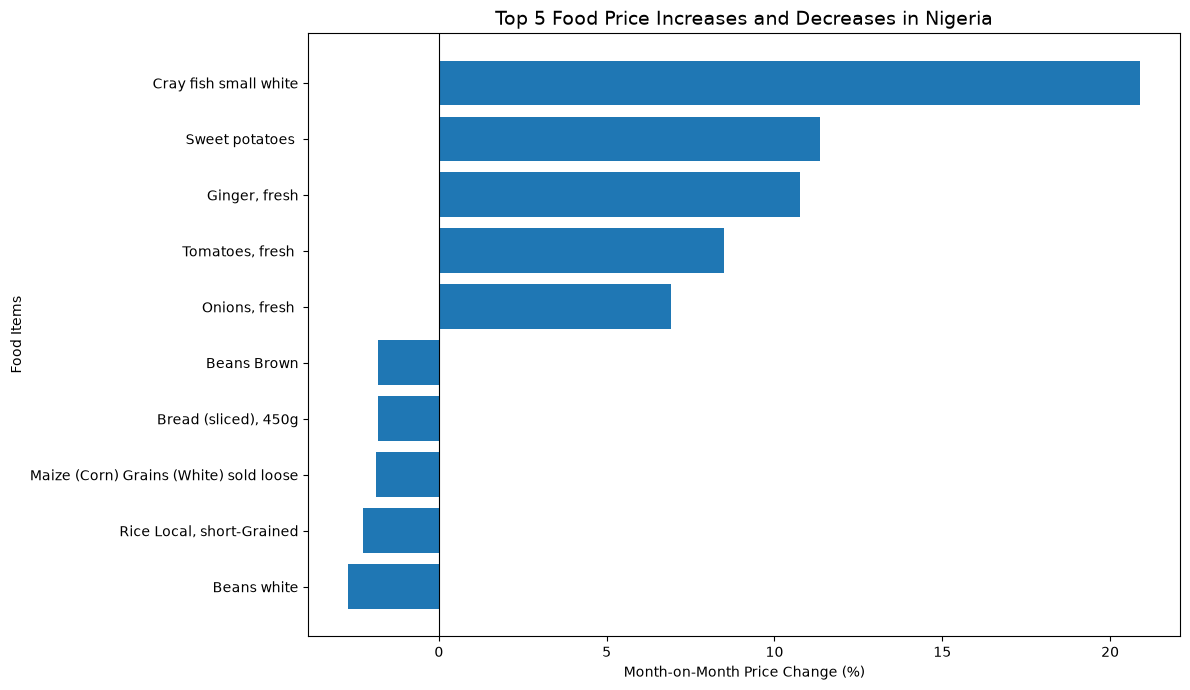

In [24]:
import matplotlib.pyplot as plt

# Combine the top increases and decreases
top_changes = pd.concat([
    highest_increases,
    highest_decreases
])

# Sort for better chart presentation
top_changes = top_changes.sort_values(by="MoM")

plt.figure(figsize=(12, 7))

plt.barh(
    top_changes["Item Label"],
    top_changes["MoM"]
)

plt.axvline(x=0, color="black", linewidth=0.8)

plt.title(
    "Top 5 Food Price Increases and Decreases in Nigeria",
    fontsize=14
)

plt.xlabel("Month-on-Month Price Change (%)")
plt.ylabel("Food Items")

plt.tight_layout()
plt.show()

In [25]:
# Calculate the average price across all food items in each zone

zone_averages = df_zone.mean(numeric_only=True)

# Arrange the zones from highest average to lowest
zone_averages = zone_averages.sort_values(ascending=False)

display(zone_averages)

SOUTH EAST       3779.587406
NORTH CENTRAL    3411.304099
SOUTH SOUTH      3406.994376
SOUTH WEST       3363.938585
NORTH EAST       3008.064945
NORTH WEST       2989.737884
dtype: float64

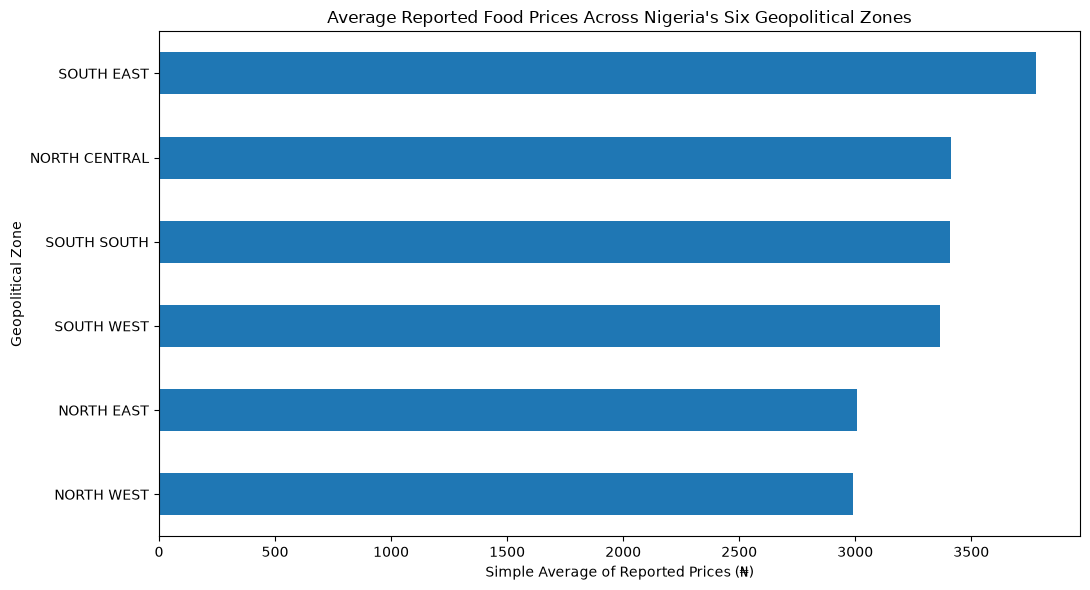

In [26]:
plt.figure(figsize=(11, 6))

zone_averages.sort_values().plot(
    kind="barh"
)

plt.title(
    "Average Reported Food Prices Across Nigeria's Six Geopolitical Zones"
)

plt.xlabel("Simple Average of Reported Prices (₦)")
plt.ylabel("Geopolitical Zone")

plt.tight_layout()
plt.show()

In [27]:
df_zone[
    df_zone["Item Label"].str.contains(
        "rice|beans|tomatoes|onions",
        case=False,
        na=False
    )
]["Item Label"]

2                      Beans Brown
3                      Beans white
21             Local Rice (Broken)
24                  Onions, fresh 
28       Rice Local, short-Grained
29    Rice Long-Grained (Imported)
37                Tomatoes, fresh 
Name: Item Label, dtype: str

In [28]:
# Create a copy so we don't alter our original dataset
df_zone_clean = df_zone.copy()

# Remove accidental spaces around food-item names
df_zone_clean["Item Label"] = (
    df_zone_clean["Item Label"].str.strip()
)

# Select the seven food items
food_items = [
    "Beans Brown",
    "Beans white",
    "Onions, fresh",
    "Tomatoes, fresh",
    "Local Rice (Broken)",
    "Rice Local, short-Grained",
    "Rice Long-Grained (Imported)"
]

# Filter the dataset
food_comparison = df_zone_clean[
    df_zone_clean["Item Label"].isin(food_items)
]

# Make food names the row labels
food_comparison = food_comparison.set_index("Item Label")

# Display the comparison
display(food_comparison.round(2))

,NORTH CENTRAL,NORTH EAST,NORTH WEST,SOUTH EAST,SOUTH SOUTH,SOUTH WEST
Item Label,,,,,,
Beans Brown,2608.53,2421.51,1766.23,3166.03,2269.07,2275.61
Beans white,2052.67,2141.81,1580.28,2705.75,2120.60,1827.49
Local Rice (Broken),2861.43,1921.68,1974.89,2323.84,3255.24,3133.20
"Onions, fresh",1299.75,1289.88,1289.63,2128.74,2262.12,1565.28
"Rice Local, short-Grained",2127.47,1944.40,2210.64,2243.18,2011.63,2034.46
Rice Long-Grained (Imported),2679.78,2403.41,2670.65,2690.50,2832.90,2341.68
"Tomatoes, fresh",1156.31,1284.41,1063.93,1965.64,1496.96,1578.70


<Figure size 1600x800 with 0 Axes>

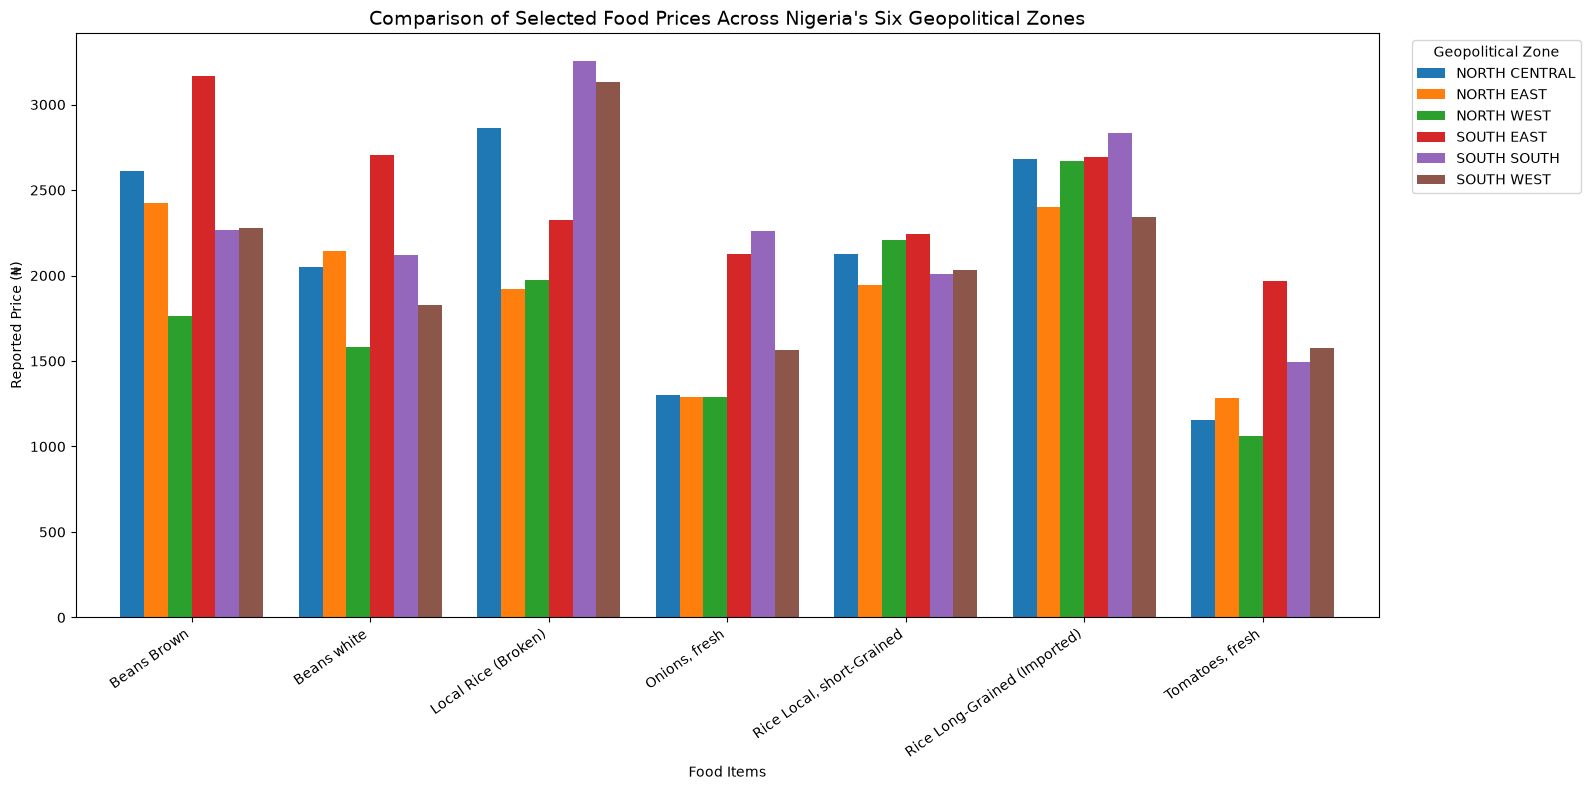

In [29]:
plt.figure(figsize=(16, 8))

food_comparison.plot(
    kind="bar",
    figsize=(16, 8),
    width=0.8
)

plt.title(
    "Comparison of Selected Food Prices Across Nigeria's Six Geopolitical Zones",
    fontsize=14
)

plt.xlabel("Food Items")
plt.ylabel("Reported Price (₦)")

plt.xticks(rotation=35, ha="right")

plt.legend(
    title="Geopolitical Zone",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

plt.tight_layout()
plt.show()

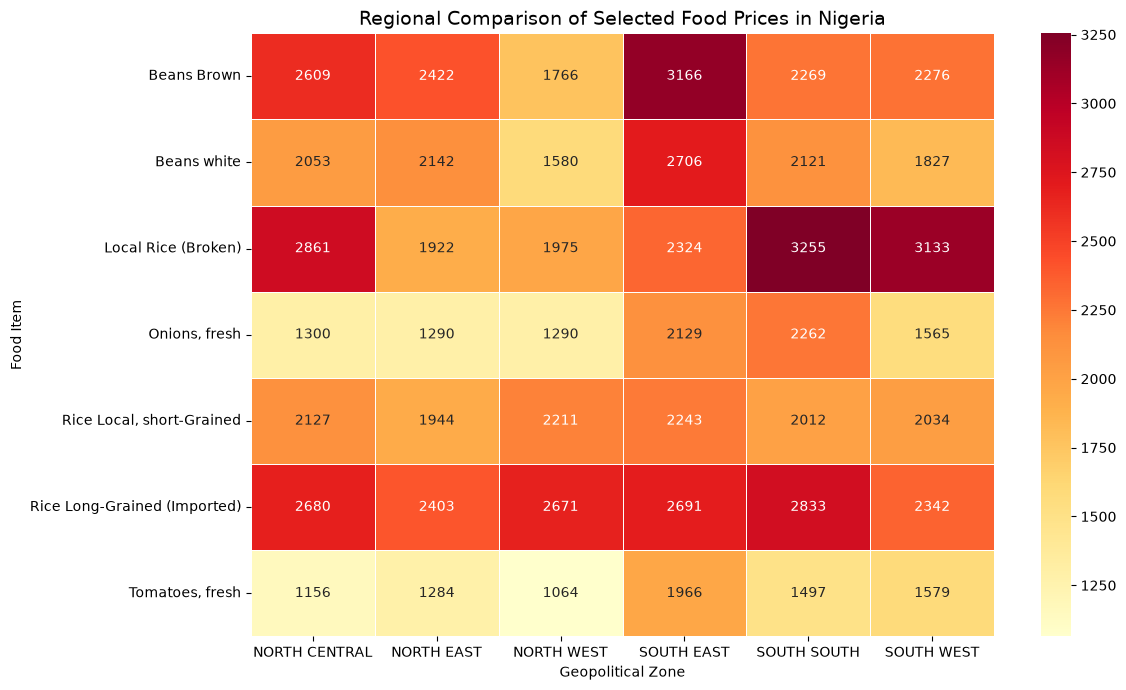

In [30]:
plt.figure(figsize=(12, 7))

sns.heatmap(
    food_comparison,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5
)

plt.title(
    "Regional Comparison of Selected Food Prices in Nigeria",
    fontsize=14
)

plt.xlabel("Geopolitical Zone")
plt.ylabel("Food Item")

plt.tight_layout()
plt.show()

In [31]:
# Find the highest and lowest prices for each food item

regional_analysis = pd.DataFrame()

regional_analysis["Highest Price"] = food_comparison.max(axis=1)

regional_analysis["Highest Price Zone"] = food_comparison.idxmax(axis=1)

regional_analysis["Lowest Price"] = food_comparison.min(axis=1)

regional_analysis["Lowest Price Zone"] = food_comparison.idxmin(axis=1)

# Calculate the difference in Naira

regional_analysis["Price Difference"] = (
    regional_analysis["Highest Price"]
    - regional_analysis["Lowest Price"]
)

# Calculate percentage difference

regional_analysis["Percentage Difference"] = (
    regional_analysis["Price Difference"]
    / regional_analysis["Lowest Price"]
) * 100

display(regional_analysis.round(2))

,Highest Price,Highest Price Zone,Lowest Price,Lowest Price Zone,Price Difference,Percentage Difference
Item Label,,,,,,
Beans Brown,3166.03,SOUTH EAST,1766.23,NORTH WEST,1399.80,79.25
Beans white,2705.75,SOUTH EAST,1580.28,NORTH WEST,1125.48,71.22
Local Rice (Broken),3255.24,SOUTH SOUTH,1921.68,NORTH EAST,1333.56,69.40
"Onions, fresh",2262.12,SOUTH SOUTH,1289.63,NORTH WEST,972.49,75.41
"Rice Local, short-Grained",2243.18,SOUTH EAST,1944.40,NORTH EAST,298.78,15.37
Rice Long-Grained (Imported),2832.90,SOUTH SOUTH,2341.68,SOUTH WEST,491.22,20.98
"Tomatoes, fresh",1965.64,SOUTH EAST,1063.93,NORTH WEST,901.72,84.75


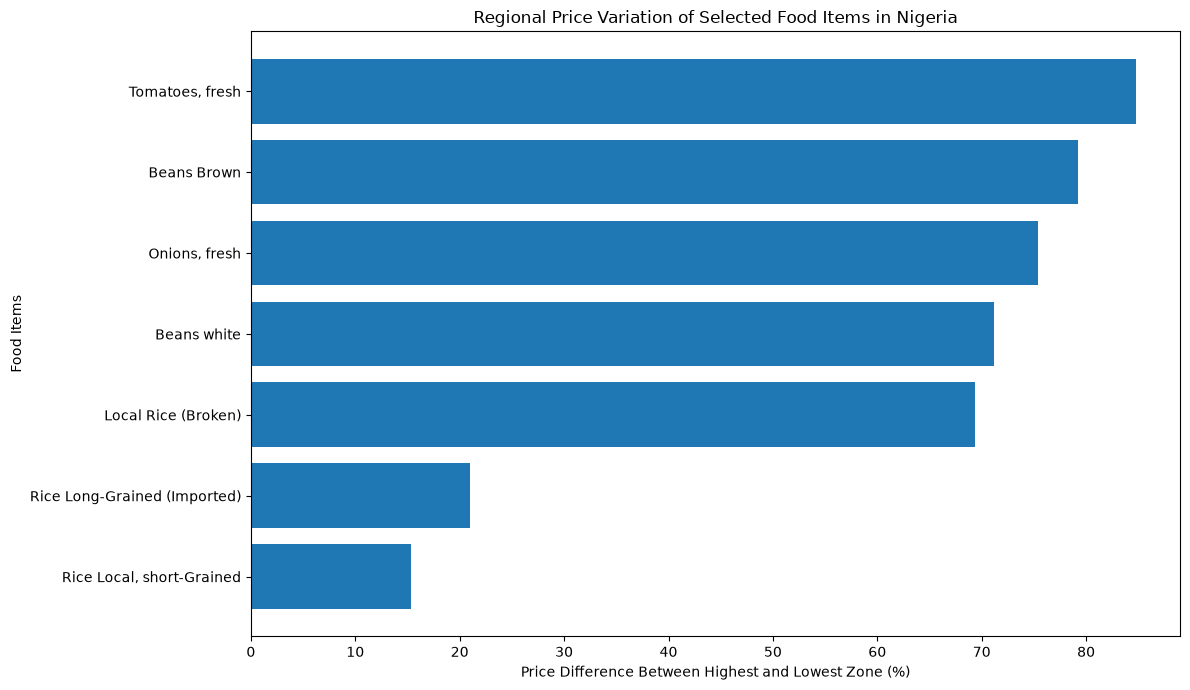

In [21]:
# Sort food items by percentage difference
price_variation = regional_analysis.sort_values(
    by="Percentage Difference",
    ascending=True
)

# Create horizontal bar chart
plt.figure(figsize=(12, 7))

plt.barh(
    price_variation.index,
    price_variation["Percentage Difference"]
)

plt.title(
    "Regional Price Variation of Selected Food Items in Nigeria"
)

plt.xlabel("Price Difference Between Highest and Lowest Zone (%)")
plt.ylabel("Food Items")

plt.tight_layout()
plt.show()

In [32]:
highest_zone_counts = (
    regional_analysis["Highest Price Zone"]
    .value_counts()
)

print("Number of times each zone recorded the highest price:")
display(highest_zone_counts)

Number of times each zone recorded the highest price:


Highest Price Zone
SOUTH EAST     4
SOUTH SOUTH    3
Name: count, dtype: int64

In [33]:
lowest_zone_counts = (
    regional_analysis["Lowest Price Zone"]
    .value_counts()
)

print("Number of times each zone recorded the lowest price:")
display(lowest_zone_counts)

Number of times each zone recorded the lowest price:


Lowest Price Zone
NORTH WEST    4
NORTH EAST    2
SOUTH WEST    1
Name: count, dtype: int64

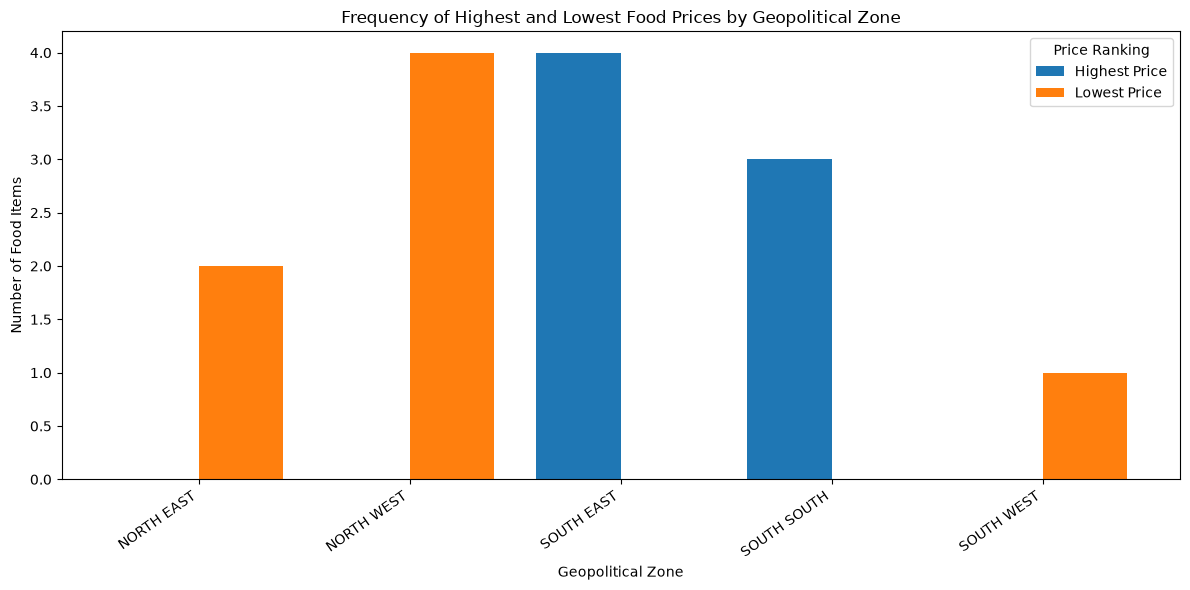

In [34]:
# Combine highest and lowest price frequencies
zone_frequency = pd.DataFrame({
    "Highest Price": highest_zone_counts,
    "Lowest Price": lowest_zone_counts
}).fillna(0)

# Create grouped bar chart
ax = zone_frequency.plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8
)

ax.set_title(
    "Frequency of Highest and Lowest Food Prices by Geopolitical Zone"
)

ax.set_xlabel("Geopolitical Zone")
ax.set_ylabel("Number of Food Items")

plt.xticks(rotation=35, ha="right")
plt.legend(title="Price Ranking")

plt.tight_layout()
plt.show()


# 21. Key Findings

## 21.1 National Food Price Movements

- Cray fish small white recorded the highest month-on-month price increase at approximately 20.90%.
- Sweet potatoes increased by approximately 11.36%.
- Ginger recorded an increase of approximately 10.77%.
- Beans white recorded the largest month-on-month decrease at approximately 2.71%.
- The five largest decreases were relatively modest compared with the largest increases.

## 21.2 Regional Food Price Analysis

- South East recorded the highest simple average across the 42 food items.
- North West recorded the lowest simple average.
- The difference between these two simple averages was approximately ₦789.85.

## 21.3 Individual Food Item Comparisons

Among the seven selected food items:

- South East recorded the highest price for four items.
- South South recorded the highest price for three items.
- North West recorded the lowest price for four items.
- North East recorded the lowest price for two items.
- South West recorded the lowest price for one item.

## 21.4 Regional Price Variation

- Fresh tomatoes recorded the largest regional price difference at approximately 84.75%.
- Beans Brown recorded a difference of approximately 79.25%.
- Rice Local, short-Grained recorded the smallest difference at approximately 15.37%.

## 21.5 Data Validation

- All 42 NBS month-on-month figures matched our independent calculations.
- All 27 available year-on-year figures matched our independent calculations.
- The 15 missing May 2024 prices corresponded exactly to the 15 missing YoY values.



# 22. Data Limitations

The following limitations should be considered when interpreting this analysis:

1. **Limited time coverage:** The analysis uses the May 2025 NBS Selected Food Price Watch dataset and does not establish long-term food-price trends.

2. **Missing historical values:** Fifteen food items have no May 2024 prices or corresponding YoY values.

3. **Different measurement units:** Food products are reported in different quantities and units. Therefore, simple averages across all food items should not be interpreted as official food-price indices.

4. **Limited regional comparison:** The detailed regional comparison focuses on seven selected food items out of the 42 available products.

5. **Descriptive analysis:** The project identifies price differences and patterns but does not establish the causes of those differences.

6. **No official inflation calculation:** The analysis does not reproduce Nigeria's official Consumer Price Index or food inflation methodology.


In [35]:
from pathlib import Path

# Identify the project directory
cwd = Path.cwd()

if cwd.name == "src":
    BASE_DIR = cwd.parent
elif (cwd / "data" / "raw").exists():
    BASE_DIR = cwd
else:
    raise FileNotFoundError(
        "Cannot identify the project directory. "
        "Check your Jupyter working directory."
    )

# Create output directories if they don't exist
VISUALS_DIR = BASE_DIR / "visuals"
PROCESSED_DIR = BASE_DIR / "data" / "processed"

VISUALS_DIR.mkdir(parents=True, exist_ok=True)
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)

print("Project directory:", BASE_DIR)
print("Visuals directory:", VISUALS_DIR)
print("Processed data directory:", PROCESSED_DIR)

Project directory: C:\Users\DELL\Documents\capstone-1-nigerian-economic-data-explorer
Visuals directory: C:\Users\DELL\Documents\capstone-1-nigerian-economic-data-explorer\visuals
Processed data directory: C:\Users\DELL\Documents\capstone-1-nigerian-economic-data-explorer\data\processed


In [36]:
# Save national food-price analysis
df_main.to_csv(
    PROCESSED_DIR / "national_food_price_analysis.csv",
    index=False
)

# Save regional food-price data
df_zone_clean.to_csv(
    PROCESSED_DIR / "regional_food_prices.csv",
    index=False
)

# Save selected food-item comparison
food_comparison.to_csv(
    PROCESSED_DIR / "selected_food_regional_comparison.csv"
)

# Save regional price variation analysis
regional_analysis.to_csv(
    PROCESSED_DIR / "regional_price_variation.csv"
)

print("All processed datasets saved successfully!")

All processed datasets saved successfully!


In [37]:
for file in PROCESSED_DIR.iterdir():
    print(file.name)

national_food_price_analysis.csv
regional_food_prices.csv
regional_price_variation.csv
selected_food_regional_comparison.csv


In [38]:
print("Visuals folder:", VISUALS_DIR)
print("Files currently inside:", list(VISUALS_DIR.iterdir()))

Visuals folder: C:\Users\DELL\Documents\capstone-1-nigerian-economic-data-explorer\visuals
Files currently inside: []


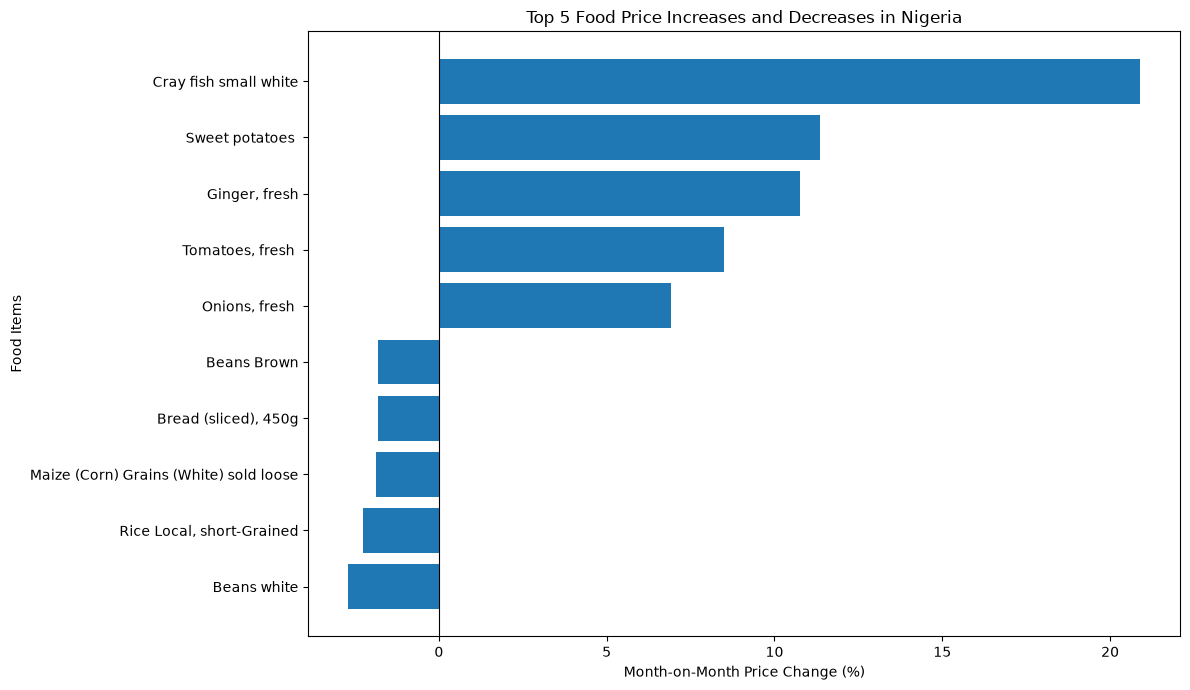

In [39]:
fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    top_changes["Item Label"],
    top_changes["MoM"]
)

ax.axvline(x=0, color="black", linewidth=0.8)

ax.set_title(
    "Top 5 Food Price Increases and Decreases in Nigeria"
)
ax.set_xlabel("Month-on-Month Price Change (%)")
ax.set_ylabel("Food Items")

fig.tight_layout()

fig.savefig(
    VISUALS_DIR / "national_food_price_changes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [40]:
print(list(VISUALS_DIR.iterdir()))

[WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/national_food_price_changes.png')]


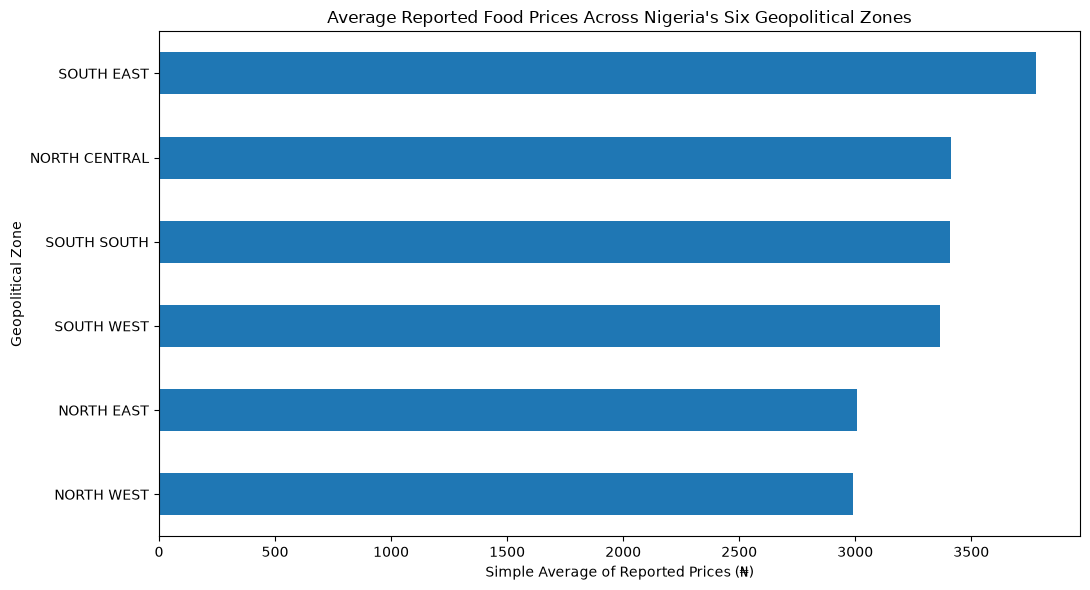

In [41]:
fig, ax = plt.subplots(figsize=(11, 6))

zone_averages.sort_values().plot(
    kind="barh",
    ax=ax
)

ax.set_title(
    "Average Reported Food Prices Across Nigeria's Six Geopolitical Zones"
)
ax.set_xlabel("Simple Average of Reported Prices (₦)")
ax.set_ylabel("Geopolitical Zone")

fig.tight_layout()

fig.savefig(
    VISUALS_DIR / "regional_average_prices.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [42]:
print(list(VISUALS_DIR.iterdir()))

[WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/national_food_price_changes.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/regional_average_prices.png')]


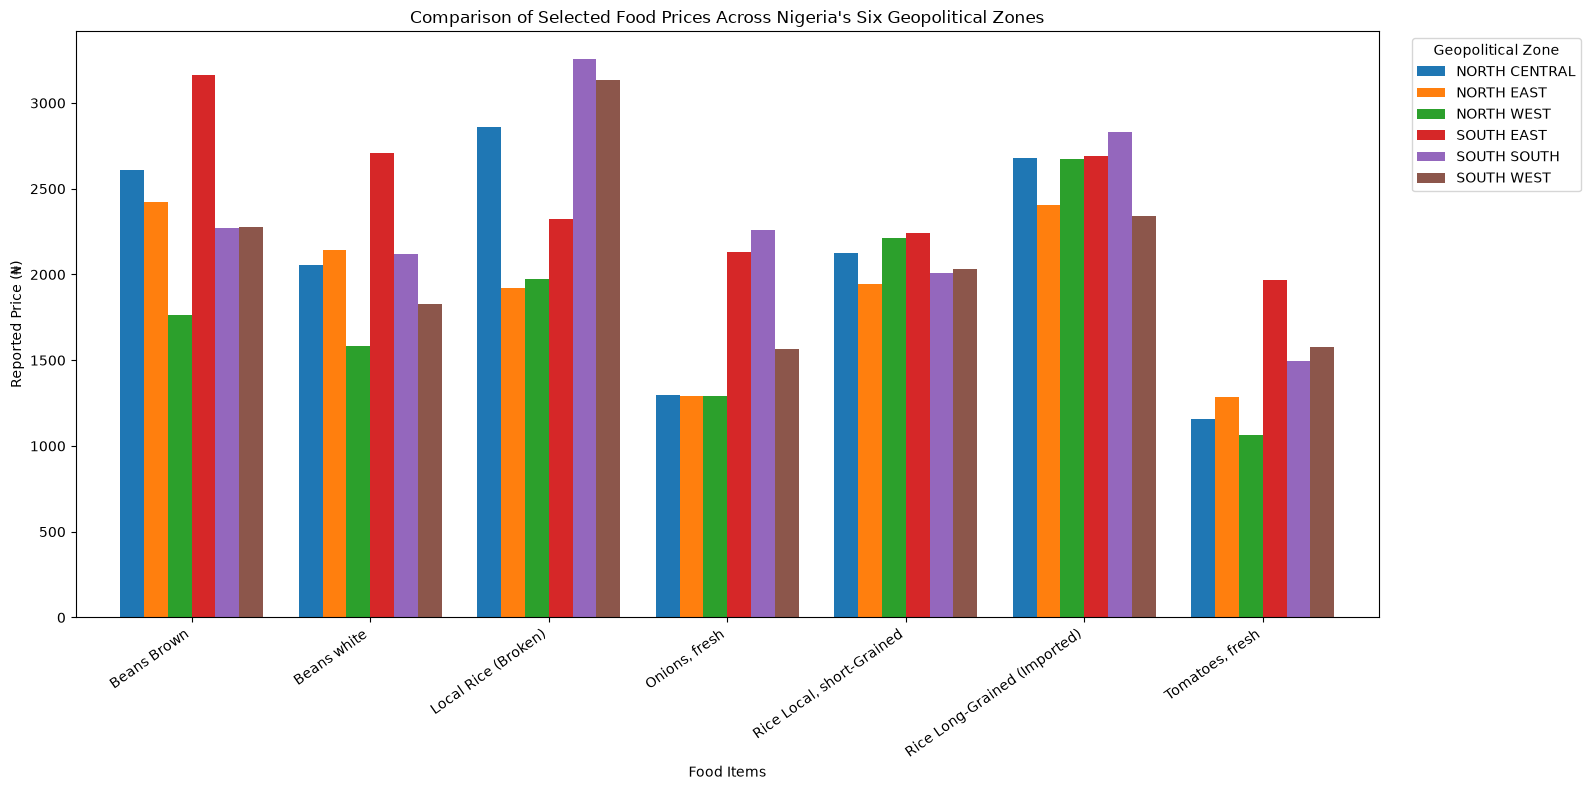

In [43]:
fig, ax = plt.subplots(figsize=(16, 8))

food_comparison.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

ax.set_title(
    "Comparison of Selected Food Prices Across Nigeria's Six Geopolitical Zones"
)
ax.set_xlabel("Food Items")
ax.set_ylabel("Reported Price (₦)")

plt.xticks(rotation=35, ha="right")

ax.legend(
    title="Geopolitical Zone",
    bbox_to_anchor=(1.02, 1),
    loc="upper left"
)

fig.tight_layout()

fig.savefig(
    VISUALS_DIR / "selected_food_grouped_comparison.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [44]:
print(list(VISUALS_DIR.iterdir()))

[WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/national_food_price_changes.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/regional_average_prices.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/selected_food_grouped_comparison.png')]


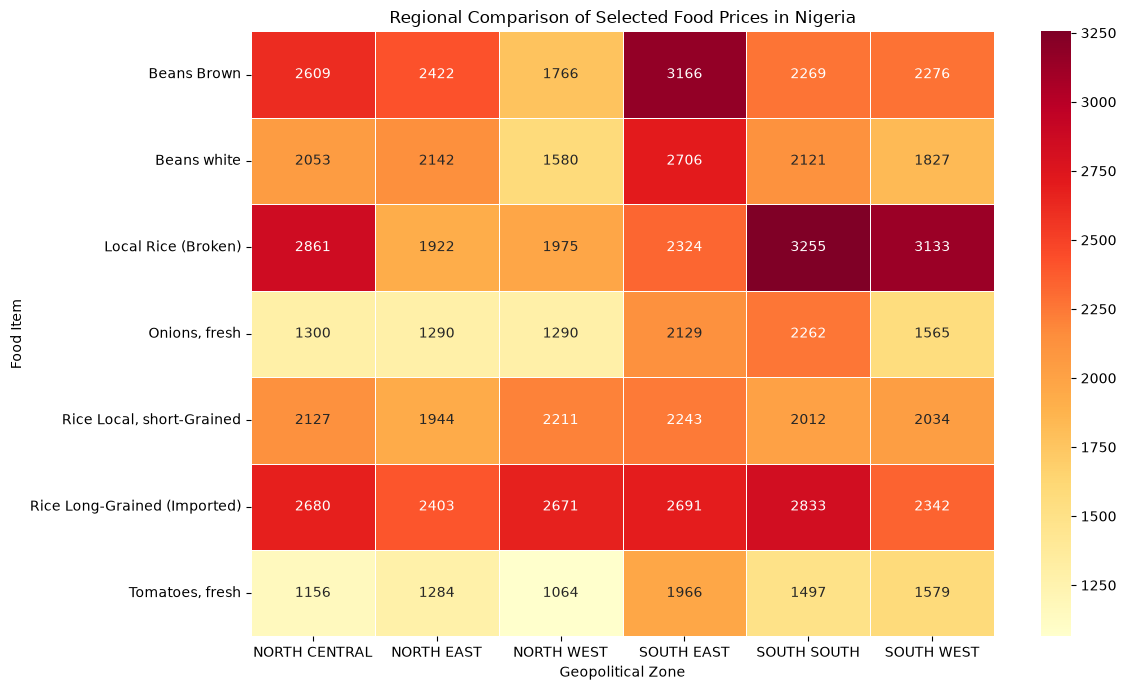

In [45]:
fig, ax = plt.subplots(figsize=(12, 7))

sns.heatmap(
    food_comparison,
    annot=True,
    fmt=".0f",
    cmap="YlOrRd",
    linewidths=0.5,
    ax=ax
)

ax.set_title(
    "Regional Comparison of Selected Food Prices in Nigeria"
)
ax.set_xlabel("Geopolitical Zone")
ax.set_ylabel("Food Item")

fig.tight_layout()

fig.savefig(
    VISUALS_DIR / "selected_food_regional_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [46]:
print(list(VISUALS_DIR.iterdir()))

[WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/national_food_price_changes.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/regional_average_prices.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/selected_food_grouped_comparison.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/selected_food_regional_heatmap.png')]


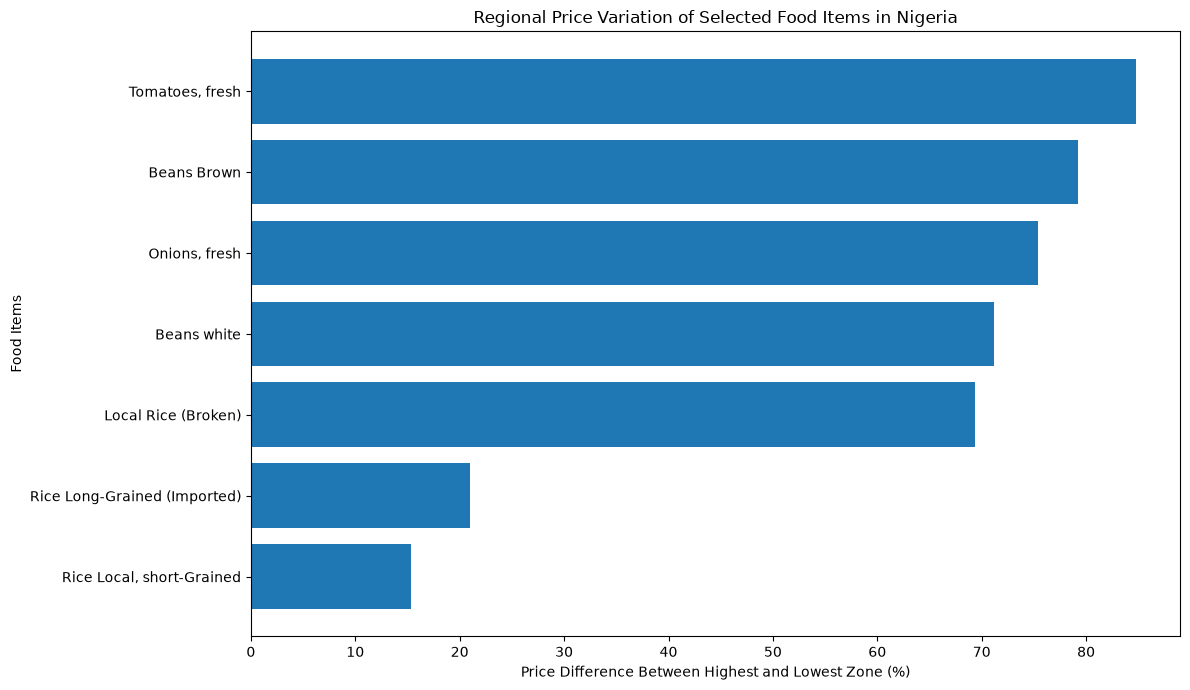

In [47]:
price_variation = regional_analysis.sort_values(
    by="Percentage Difference",
    ascending=True
)

fig, ax = plt.subplots(figsize=(12, 7))

ax.barh(
    price_variation.index,
    price_variation["Percentage Difference"]
)

ax.set_title(
    "Regional Price Variation of Selected Food Items in Nigeria"
)
ax.set_xlabel("Price Difference Between Highest and Lowest Zone (%)")
ax.set_ylabel("Food Items")

fig.tight_layout()

fig.savefig(
    VISUALS_DIR / "regional_price_variation.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [48]:
print(list(VISUALS_DIR.iterdir()))

[WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/national_food_price_changes.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/regional_average_prices.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/regional_price_variation.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/selected_food_grouped_comparison.png'), WindowsPath('C:/Users/DELL/Documents/capstone-1-nigerian-economic-data-explorer/visuals/selected_food_regional_heatmap.png')]


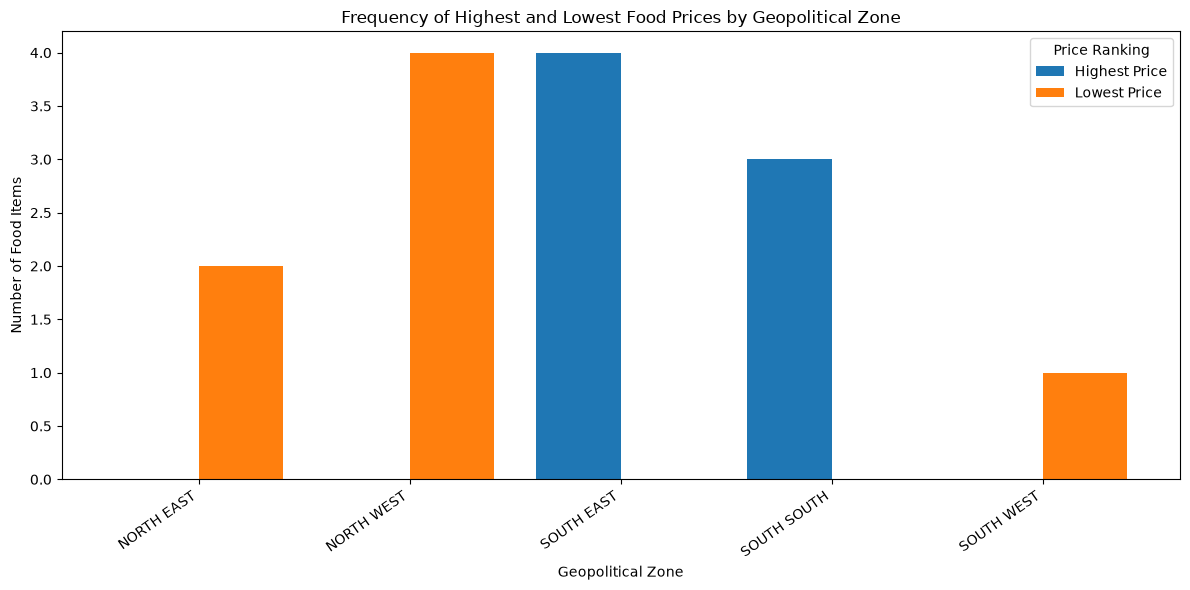

In [49]:
zone_frequency = pd.DataFrame({
    "Highest Price": highest_zone_counts,
    "Lowest Price": lowest_zone_counts
}).fillna(0)

fig, ax = plt.subplots(figsize=(12, 6))

zone_frequency.plot(
    kind="bar",
    ax=ax,
    width=0.8
)

ax.set_title(
    "Frequency of Highest and Lowest Food Prices by Geopolitical Zone"
)
ax.set_xlabel("Geopolitical Zone")
ax.set_ylabel("Number of Food Items")

plt.xticks(rotation=35, ha="right")

ax.legend(title="Price Ranking")

fig.tight_layout()

fig.savefig(
    VISUALS_DIR / "regional_highest_lowest_frequency.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [50]:
for file in sorted(VISUALS_DIR.iterdir()):
    print(file.name)

national_food_price_changes.png
regional_average_prices.png
regional_highest_lowest_frequency.png
regional_price_variation.png
selected_food_grouped_comparison.png
selected_food_regional_heatmap.png


In [52]:
requirements_path = BASE_DIR / "requirements.txt"

print(requirements_path.read_text())

In [53]:
requirements = """pandas
numpy
matplotlib
seaborn
openpyxl
jupyter
"""

requirements_path.write_text(requirements)

print("Requirements file updated successfully!")
print(requirements_path.read_text())

Requirements file updated successfully!
pandas
numpy
matplotlib
seaborn
openpyxl
jupyter



In [54]:
gitignore_path = BASE_DIR / ".gitignore"

gitignore_content = """# Python virtual environment
.venv/

# Python cache files
__pycache__/
*.py[cod]

# Jupyter Notebook checkpoints
.ipynb_checkpoints/

# Environment variables
.env

# Operating system files
.DS_Store
Thumbs.db
"""

gitignore_path.write_text(gitignore_content)

print(".gitignore created successfully!")
print(gitignore_path.read_text())

.gitignore created successfully!
# Python virtual environment
.venv/

# Python cache files
__pycache__/
*.py[cod]

# Jupyter Notebook checkpoints
.ipynb_checkpoints/

# Environment variables
.env

# Operating system files
.DS_Store
Thumbs.db



In [55]:
for item in sorted(BASE_DIR.iterdir()):
    print(item.name, "/" if item.is_dir() else "")

.gitignore 
.ipynb_checkpoints /
.venv /
data /
README.md 
reports /
requirements.txt 
src /
Untitled.ipynb 
visuals /


In [56]:
print("NOTEBOOKS IN SRC:")
for file in (BASE_DIR / "src").glob("*.ipynb"):
    print(file.name)

print("\nFILES IN DATA/RAW:")
for file in (BASE_DIR / "data" / "raw").iterdir():
    print(file.name)

print("\nFILES IN DATA/PROCESSED:")
for file in (BASE_DIR / "data" / "processed").iterdir():
    print(file.name)

NOTEBOOKS IN SRC:
01_nigerian_food_price_analysis.ipynb

FILES IN DATA/RAW:
selected_food_table_May-25.xlsx

FILES IN DATA/PROCESSED:
national_food_price_analysis.csv
regional_food_prices.csv
regional_price_variation.csv
selected_food_regional_comparison.csv
